# **Lab 7(A) - Laplacian Filter (Colored Image)**

This is the colored-image version of the Lab 7(A) notebook. 

**What changed compared with the grayscale notebook**
- The image is loaded in **color** (`cv2.imread(file)` instead of `cv2.imread(file, 0)`), so it has 3 channels (B, G, R).
- `cv2.filter2D` and `cv2.Laplacian` apply the kernel to **each color channel independently**, so the same code works unchanged.
- OpenCV stores color as **BGR**, so images are converted to **RGB** before being shown with matplotlib (otherwise red and blue are swapped).
- The raw Laplacian contains negative values, so it is scaled to 0..1 before being displayed in color.
- `img + laplacian_abs` on two `uint8` arrays wraps around past 255 (a bright pixel turns dark). `cv2.add` is used instead because it saturates at 255.

### Step 0: Install packages and download the colored sample image 

In [1]:
%pip install -q opencv-python numpy matplotlib

import os

images_dir = os.path.join(os.getcwd(), 'images')
os.makedirs(images_dir, exist_ok=True)

# A colored sample image (the same parrot image used in earlier labs)
url = 'https://raw.githubusercontent.com/PacktPublishing/Hands-On-Image-Processing-with-Python/master/images/parrot.png'
dest = os.path.join(images_dir, 'Parrot.png')

!curl -L -s -o "{dest}" "{url}"
size = os.path.getsize(dest) if os.path.exists(dest) else 0
print(f'Parrot.png: {"OK" if size > 0 else "FAILED"} ({size} bytes) -> {dest}')

Note: you may need to restart the kernel to use updated packages.
Parrot.png: OK (215272 bytes) -> c:\Users\dania\Image_Processing_Labs\Lab7\images\Parrot.png


In [2]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# OpenCV loads color images as BGR, but matplotlib expects RGB -> reverse the channel order for display
def rgb(img):
    return img[:, :, ::-1]

# Scale any array (e.g. a Laplacian with negative values) to 0..1 so it can be displayed in color
def norm01(a):
    a = a.astype(np.float64)
    return (a - a.min()) / (a.max() - a.min() + 1e-12)

## Apply Laplacian Filter on Image to get Sharp Image

Image shape: (340, 453, 3)


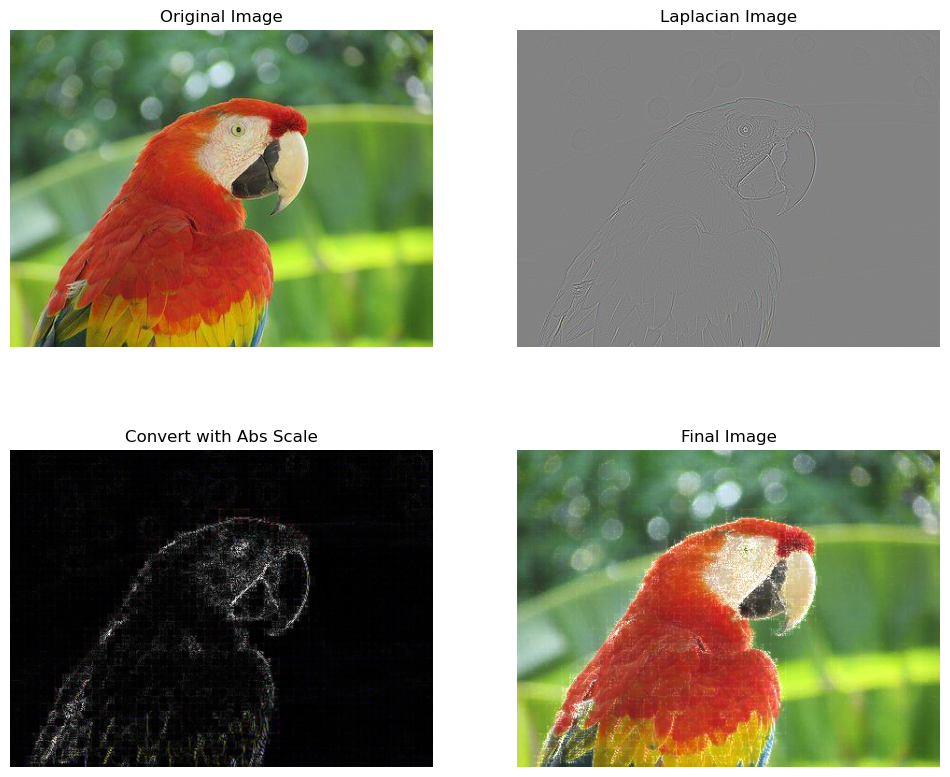

In [3]:
# ================ ( Laplacian Filter ) ===================


# 0. Image file path (a colored image; change this to use your own image)
imgFile = os.path.join('images', 'Parrot.png')

# 1. Load image in COLOR (OpenCV gives a height x width x 3 array in B, G, R order)
img = cv2.imread(imgFile, cv2.IMREAD_COLOR)
print('Image shape:', img.shape)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D (the kernel is applied to each of the B, G, R channels separately)
# For Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# Saturating add (cv2.add) instead of img + laplacian_abs, which would wrap around past 255
finalImage = cv2.add(img, laplacian_abs)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(rgb(img)), plt.title('Original Image')
plt.subplot(222), plt.imshow(rgb(norm01(laplacian_manual))), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(rgb(laplacian_abs)), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(rgb(finalImage)), plt.title('Final Image')
for ax in plt.gcf().axes: ax.axis('off')
plt.show()

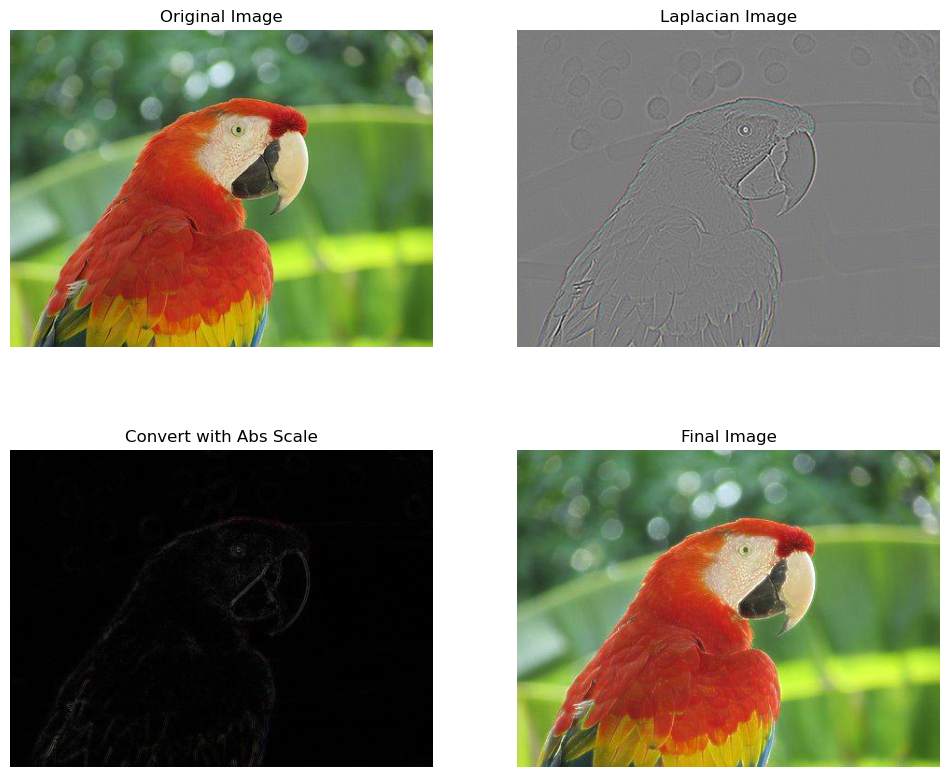

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm (on each color channel)
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and original Image (saturating add)
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(rgb(img)), plt.title('Original Image')
plt.subplot(222), plt.imshow(rgb(norm01(laplacian))), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(rgb(laplacian_8bit)), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(rgb(finalImage2)), plt.title('Final Image')
for ax in plt.gcf().axes: ax.axis('off')
plt.show()

## Extra (optional): color-preserving sharpening

Filtering the B, G and R channels separately can slightly shift colors along edges. A common alternative for color images is to filter only the **brightness (luminance)** channel and leave the color channels untouched.

For this Laplacian kernel (negative center), the standard sharpening formula is `sharpened = original - Laplacian`.

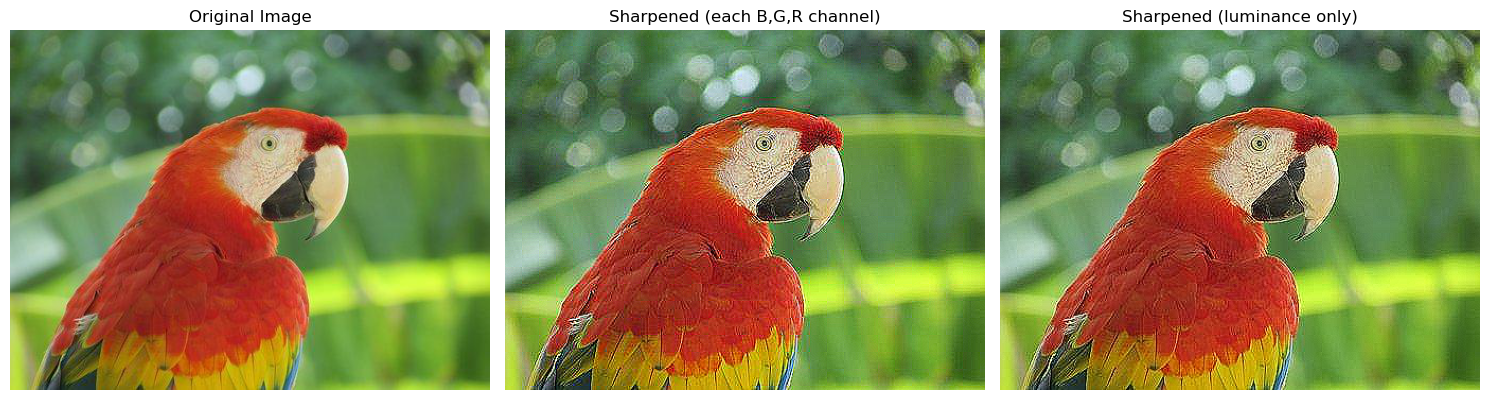

In [5]:
# Convert to YCrCb: Y = brightness, Cr/Cb = color information
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
Y, Cr, Cb = cv2.split(ycrcb)

# Laplacian on the brightness channel only
lap_Y = cv2.Laplacian(Y, cv2.CV_64F)

# Sharpen: original - Laplacian (for the negative-center kernel)
Y_sharp = np.clip(Y.astype(np.float64) - lap_Y, 0, 255).astype(np.uint8)
luma_sharpened = cv2.cvtColor(cv2.merge([Y_sharp, Cr, Cb]), cv2.COLOR_YCrCb2BGR)

# Same idea, per channel, for comparison
channel_sharpened = np.clip(img.astype(np.float64) - cv2.Laplacian(img, cv2.CV_64F), 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(rgb(img)), plt.title('Original Image')
plt.subplot(132), plt.imshow(rgb(channel_sharpened)), plt.title('Sharpened (each B,G,R channel)')
plt.subplot(133), plt.imshow(rgb(luma_sharpened)), plt.title('Sharpened (luminance only)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()